# Multi-Factor Stock Classification with TOPSIS and VIKOR

**Coding for Finance**

A junior quant analyst is asked to classify a universe of 20 US-listed stocks on return, risk and risk-adjusted performance, then rank them with two independent multi-criteria decision methods — **TOPSIS** and **VIKOR** — to see whether they agree on the best pick.

**Data.** Monthly adjusted closing prices from Yahoo Finance (downloaded with the `yfinance` library) from September 2023 to September 2026: 37 prices, i.e. 36 monthly returns per stock. The risk-free rate is the average yield of the 13-week US Treasury bill (`^IRX`) over the same window. The first run downloads the data and saves a local copy in `data/` (not tracked by git, because the data are not redistributed); later runs read the local copy.

**Measures**, annualised from monthly returns: Return = mean monthly return × 12; Risk = standard deviation of monthly returns × √12; Sharpe = (Return − Rf) / Risk; Maximum drawdown computed on month-end prices; Mean-Variance score μ − λσ² with λ = 3.

**Note on the data and results.** This is a teaching exercise and the data are used for illustration only. They are real monthly prices, but the time window, the 20-stock universe, the criteria weights and the classification thresholds are exercise choices, so the output shows how TOPSIS and VIKOR work and is not investment advice or a view on any stock.

Requirements: `numpy`, `pandas`, `matplotlib`, `yfinance`.

## 1. Data and risk measures

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA",
           "META", "NVDA", "JPM", "V", "NFLX",
           "ORCL", "INTC", "AMD", "GS", "BAC",
           "WMT", "KO", "PEP", "DIS", "CSCO"]
START, END = "2023-09-01", "2026-10-01"      # monthly bars Sep 2023 - Sep 2026 (END is exclusive)
CACHE = "data/monthly_prices.csv"

def load_prices():
    """Monthly adjusted closes of the universe plus the 13-week T-bill yield (^IRX).
    First run: download from Yahoo Finance and save a local copy. Later runs: read the copy."""
    if os.path.exists(CACHE):
        return pd.read_csv(CACHE, index_col=0, parse_dates=True)
    import yfinance as yf
    raw = yf.download(TICKERS + ["^IRX"], start=START, end=END, interval="1mo",
                      auto_adjust=True, progress=False)
    if raw.empty:
        raise RuntimeError("Yahoo Finance returned no data: check the connection and retry")
    raw = raw["Close"]
    raw.index = pd.DatetimeIndex(raw.index).tz_localize(None)         # tz-naive month-start dates
    missing = [t for t in TICKERS if t not in raw.columns or raw[t].isna().all()]
    if missing:
        raise RuntimeError(f"No data downloaded for {missing}: retry later (nothing was saved)")
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    raw.to_csv(CACHE)                                                 # only a complete download is cached
    return raw

data = load_prices()
prices = data[TICKERS]
prices = prices[(prices.index >= START) & (prices.index < END)].dropna()
assert len(prices) >= 31, "Fewer than 30 monthly returns: check the download"

if "^IRX" in data.columns and data["^IRX"].notna().any():
    risk_free_rate = data["^IRX"].dropna().mean() / 100       # ^IRX is quoted in percent
else:
    risk_free_rate = 0.04
    print("Warning: ^IRX not available, using Rf = 4%")

rets = prices.pct_change().dropna()                           # simple monthly returns
stocks = list(prices.columns)

returns = (rets.mean() * 12).to_numpy()                       # annualised mean return
risks = (rets.std(ddof=1) * np.sqrt(12)).to_numpy()           # annualised volatility
sharpe_ratios = (returns - risk_free_rate) / risks
max_drawdown = (prices / prices.cummax() - 1).min().to_numpy()   # <= 0

lambda_risk_aversion = 3
mv_scores = returns - lambda_risk_aversion * risks ** 2

print(f"{len(rets)} monthly returns per stock, {prices.index[0]:%b %Y} - {prices.index[-1]:%b %Y}; "
      f"Rf = {risk_free_rate:.2%}")

36 monthly returns per stock, Sep 2023 - Sep 2026; Rf = 4.36%


## 2. Classification

Each stock is labelled with a rule-based system combining Return, Risk and the Sharpe ratio. The thresholds are illustrative design choices, evaluated in the order shown:

| Class | Rule |
|---|---|
| Excellent | Return > 10%, Risk < 30%, Sharpe > 1.0 |
| Good | Return ≥ 5%, Risk < 30%, Sharpe > 0.5 |
| Risky | Return ≥ 5% and Risk ≥ 30% |
| Moderate | Return ≥ 0% (none of the above) |
| Avoid | Return < 0% |

The rules are applied row by row with a loop; the TOPSIS/VIKOR ranking further down is fully vectorised.

In [2]:
RET_EXCELLENT, RET_GOOD, RISK_MAX = 0.10, 0.05, 0.30
SHARPE_EXCELLENT, SHARPE_GOOD = 1.0, 0.5

def classify(r, risk, sharpe):
    if r > RET_EXCELLENT and risk < RISK_MAX and sharpe > SHARPE_EXCELLENT:
        return "Excellent"
    if r >= RET_GOOD and risk < RISK_MAX and sharpe > SHARPE_GOOD:
        return "Good"
    if r >= RET_GOOD and risk >= RISK_MAX:
        return "Risky"
    if r >= 0:
        return "Moderate"
    return "Avoid"

investment_class = []
for i in range(len(stocks)):
    investment_class.append(classify(returns[i], risks[i], sharpe_ratios[i]))

summary_df = pd.DataFrame({
    "Stock": stocks, "Return": returns, "Risk": risks, "Sharpe": sharpe_ratios,
    "Max drawdown": max_drawdown, "MV score": mv_scores, "Class": investment_class,
})
print(summary_df.sort_values("Sharpe", ascending=False).round(3).to_string(index=False))
print()
print(summary_df["Class"].value_counts().to_string())

Stock  Return  Risk  Sharpe  Max drawdown  MV score     Class
 NVDA   0.630 0.372   1.575        -0.216     0.214     Risky
   GS   0.401 0.258   1.384        -0.143     0.201 Excellent
  JPM   0.320 0.199   1.384        -0.083     0.200 Excellent
  AMD   0.819 0.726   1.069        -0.494    -0.760     Risky
GOOGL   0.376 0.316   1.050        -0.241     0.076     Risky
  WMT   0.255 0.204   1.040        -0.209     0.131 Excellent
  BAC   0.281 0.229   1.036        -0.151     0.124 Excellent
 CSCO   0.288 0.250   0.978        -0.115     0.101      Good
 AAPL   0.249 0.211   0.977        -0.196     0.116      Good
   KO   0.184 0.150   0.938        -0.128     0.117      Good
 META   0.357 0.348   0.901        -0.278    -0.007     Risky
    V   0.169 0.158   0.796        -0.168     0.095      Good
 AMZN   0.266 0.290   0.766        -0.224     0.014      Good
 INTC   0.714 0.876   0.766        -0.608    -1.586     Risky
 NFLX   0.265 0.351   0.630        -0.480    -0.105     Risky
 MSFT   

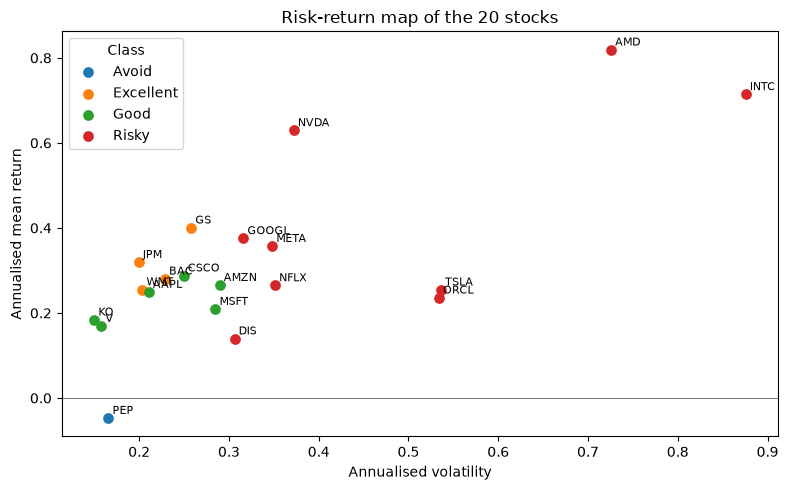

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for cls, grp in summary_df.groupby("Class"):
    ax.scatter(grp["Risk"], grp["Return"], label=cls, s=45)
for _, row in summary_df.iterrows():
    ax.annotate(row["Stock"], (row["Risk"], row["Return"]), fontsize=8,
                xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Annualised volatility")
ax.set_ylabel("Annualised mean return")
ax.set_title("Risk-return map of the 20 stocks")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

## 3. TOPSIS and VIKOR

Both methods rank the stocks on four criteria with equal weights (0.25 each): Return (benefit), Risk (cost), Sharpe ratio (benefit) and absolute maximum drawdown (cost). The Mean-Variance score is reported above but left out of the ranking, because it is a function of return and risk and would count them twice.

**TOPSIS** ranks alternatives by their distance to an ideal point across all criteria at once:

$$\text{Closeness}_i = \frac{D_i^-}{D_i^+ + D_i^-}$$

where $D_i^+$ and $D_i^-$ are the Euclidean distances to the ideal-best and ideal-worst vectors (higher closeness = better).

**VIKOR** balances *group utility* $S$ (average gap from the best value over all criteria) against *individual regret* $R$ (the single worst gap), combined with $v = 0.5$:

$$Q_i = v\cdot\frac{S_i - S^*}{S^- - S^*} + (1-v)\cdot\frac{R_i - R^*}{R^- - R^*}$$

(lower $Q$ = better compromise).

In [4]:
def topsis(X, w, benefit):
    norm = X / np.sqrt((X ** 2).sum(axis=0))                  # vector normalisation
    V = norm * w
    best = np.where(benefit, V.max(axis=0), V.min(axis=0))
    worst = np.where(benefit, V.min(axis=0), V.max(axis=0))
    d_best = np.sqrt(((V - best) ** 2).sum(axis=1))
    d_worst = np.sqrt(((V - worst) ** 2).sum(axis=1))
    return d_worst / (d_best + d_worst)                       # closeness coefficient

def vikor(X, w, benefit, v=0.5):
    f_star = np.where(benefit, X.max(axis=0), X.min(axis=0))
    f_minus = np.where(benefit, X.min(axis=0), X.max(axis=0))
    denom = f_star - f_minus
    denom[denom == 0] = 1e-12
    d = w * (f_star - X) / denom
    S, R = d.sum(axis=1), d.max(axis=1)
    return (v * (S - S.min()) / (S.max() - S.min())
            + (1 - v) * (R - R.min()) / (R.max() - R.min()))  # compromise index Q

criteria_names = ["Return", "Risk", "Sharpe", "Max drawdown"]
X = np.column_stack([returns, risks, sharpe_ratios, np.abs(max_drawdown)])
is_benefit = np.array([True, False, True, False])
weights = np.full(4, 0.25)

print("Correlation between the criteria (they are not independent):")
print(pd.DataFrame(X, columns=criteria_names).corr().round(2))

Correlation between the criteria (they are not independent):
              Return  Risk  Sharpe  Max drawdown
Return          1.00  0.73    0.59          0.43
Risk            0.73  1.00   -0.03          0.87
Sharpe          0.59 -0.03    1.00         -0.32
Max drawdown    0.43  0.87   -0.32          1.00


In [5]:
topsis_score = topsis(X, weights, is_benefit)
vikor_q = vikor(X, weights, is_benefit)

ranking = pd.DataFrame({"Stock": stocks, "TOPSIS": topsis_score, "VIKOR Q": vikor_q})
ranking["TOPSIS rank"] = ranking["TOPSIS"].rank(ascending=False, method="min").astype(int)
ranking["VIKOR rank"] = ranking["VIKOR Q"].rank(method="min").astype(int)
print(ranking.sort_values("TOPSIS rank").round(4).to_string(index=False))

rank_corr = pd.Series(topsis_score).rank().corr(pd.Series(-vikor_q).rank())
print()
print(f"TOPSIS top pick: {stocks[int(np.argmax(topsis_score))]}  |  VIKOR top pick: {stocks[int(np.argmin(vikor_q))]}")
print(f"Rank correlation between the two methods: {rank_corr:.2f}")

Stock  TOPSIS  VIKOR Q  TOPSIS rank  VIKOR rank
 NVDA  0.7956   0.0114            1           1
   GS  0.7318   0.1541            2           2
  JPM  0.7110   0.1949            3           3
GOOGL  0.6532   0.2944            4           4
  BAC  0.6502   0.3270            5           6
 CSCO  0.6501   0.3155            6           5
  WMT  0.6319   0.3754            7           8
 AAPL  0.6249   0.3860            8           9
   KO  0.6183   0.4089            9          10
 META  0.6089   0.3640           10           7
    V  0.5905   0.4660           11          12
  AMD  0.5866   0.6356           12          14
 AMZN  0.5850   0.4365           13          11
 MSFT  0.5213   0.5611           14          13
 INTC  0.4788   0.9658           15          20
 NFLX  0.4769   0.6897           16          17
  DIS  0.4742   0.6587           17          16
 TSLA  0.4245   0.6525           18          15
  PEP  0.4025   0.9134           19          19
 ORCL  0.3631   0.8968           20     

## 4. Sensitivity to the weights

How much does the top of the ranking depend on the weights chosen for the four criteria?

In [6]:
schemes = {
    "Equal":          [0.25, 0.25, 0.25, 0.25],
    "Return-focused": [0.40, 0.20, 0.20, 0.20],
    "Risk-focused":   [0.10, 0.30, 0.20, 0.40],
}
rows = []
for name, w in schemes.items():
    w = np.array(w)
    t_top = np.argsort(-topsis(X, w, is_benefit))[:3]
    v_top = np.argsort(vikor(X, w, is_benefit))[:3]
    rows.append({"Weights": name,
                 "TOPSIS top 3": ", ".join(stocks[i] for i in t_top),
                 "VIKOR top 3": ", ".join(stocks[i] for i in v_top)})
print(pd.DataFrame(rows).to_string(index=False))

       Weights  TOPSIS top 3   VIKOR top 3
         Equal NVDA, GS, JPM NVDA, GS, JPM
Return-focused NVDA, AMD, GS NVDA, GS, AMD
  Risk-focused JPM, GS, CSCO JPM, GS, CSCO


## 5. Notes and limitations

- The results depend on the window (36 months, September 2023 – September 2026) and on the universe: the 20 stocks are today's large caps, so the sample is affected by selection (survivorship) bias.
- Return, Risk, Sharpe and Maximum drawdown are related to each other. TOPSIS and VIKOR treat them as separate criteria, so the weights express preferences rather than independent information; the sensitivity table shows how much the top of the ranking depends on them.
- The classification thresholds are illustrative design choices, not market standards.
- TOPSIS and VIKOR aggregate differently (distance to an ideal solution versus a compromise between group utility and maximum regret). Agreement between them, measured by the rank correlation, is a sign of robustness; disagreement is information about how the stocks trade off the criteria.
- Performance over the window says nothing certain about future returns.